# Fig. 5 — cross-model Kendall and Mantel agreement heatmaps

Draws the two 7 × 7 agreement matrices as a vector PDF.

- **Kendall panel:** Kendall's τ between the family rankings of the full PQS, recomputed from the `PQS` column of the seven files in `data/per_family/`.
- **Mantel panel:** Mantel *r* between the first-token JSD matrices, read from `analysis/results/mantel_pairwise_results.csv` (written by `analysis/cross_model_agreement.py`).
- Heatmap cells are vector rectangles; annotations, axes, titles and colour bars are vector text/graphics.

**How to run:** in Colab, run top to bottom and upload the files when prompted.

## Upload the per family CSVs

In [1]:

from google.colab import files

print("Upload these 7 per-family CSVs:")
print("  distilgpt2_per_family.csv")
print("  qwen2_5_0_5b_per_family.csv")
print("  qwen2_5_0_5b_instruct_per_family.csv")
print("  qwen2_5_7b_per_family.csv")
print("  qwen2_5_7b_instruct_per_family.csv")
print("  llama_3_1_8b_per_family.csv")
print("  llama_3_1_8b_instruct_per_family.csv")

uploaded_per_family = files.upload()
print("\nUploaded:", list(uploaded_per_family.keys()))


Upload these 7 per-family CSVs:
  distilgpt2_per_family.csv
  qwen2_5_0_5b_per_family.csv
  qwen2_5_0_5b_instruct_per_family.csv
  qwen2_5_7b_per_family.csv
  qwen2_5_7b_instruct_per_family.csv
  llama_3_1_8b_per_family.csv
  llama_3_1_8b_instruct_per_family.csv


Saving distilgpt2_per_family.csv to distilgpt2_per_family.csv
Saving llama_3_1_8b_instruct_per_family.csv to llama_3_1_8b_instruct_per_family.csv
Saving llama_3_1_8b_per_family.csv to llama_3_1_8b_per_family.csv
Saving qwen2_5_0_5b_instruct_per_family.csv to qwen2_5_0_5b_instruct_per_family.csv
Saving qwen2_5_0_5b_per_family.csv to qwen2_5_0_5b_per_family.csv
Saving qwen2_5_7b_instruct_per_family.csv to qwen2_5_7b_instruct_per_family.csv
Saving qwen2_5_7b_per_family.csv to qwen2_5_7b_per_family.csv

Uploaded: ['distilgpt2_per_family.csv', 'llama_3_1_8b_instruct_per_family.csv', 'llama_3_1_8b_per_family.csv', 'qwen2_5_0_5b_instruct_per_family.csv', 'qwen2_5_0_5b_per_family.csv', 'qwen2_5_7b_instruct_per_family.csv', 'qwen2_5_7b_per_family.csv']


## Upload the Mantel pairwise results CSV

In [2]:

from google.colab import files

print("Upload:")
print("  mantel_pairwise_results.csv")

uploaded_mantel = files.upload()
print("\nUploaded:", list(uploaded_mantel.keys()))


Upload:
  mantel_pairwise_results.csv


Saving mantel_pairwise_results.csv to mantel_pairwise_results.csv

Uploaded: ['mantel_pairwise_results.csv']


In [3]:

# Imports + publication settings

import io
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.stats import kendalltau, chi2
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 7.5,
    "axes.titlesize": 8.5,
    "axes.labelsize": 7.5,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": True,
})

def normalize_stem(name):
    stem = name[:-4] if name.lower().endswith(".csv") else name
    return re.sub(r"\s*\(\d+\)$", "", stem)

def resolve_uploaded(expected_name, uploaded_dict):
    target = normalize_stem(expected_name)
    matches = [name for name in uploaded_dict if normalize_stem(name) == target]
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(
            f"Missing upload: {expected_name}\nAvailable: {list(uploaded_dict.keys())}"
        )
    raise RuntimeError(
        f"Multiple uploads match {expected_name}: {matches}. "
        "Keep one copy and rerun the upload cell."
    )


In [4]:

# Build the FULL-PQS Kendall matrix

MODEL_FILES = {
    "DistilGPT-2": "distilgpt2_per_family.csv",
    "Qwen-0.5B": "qwen2_5_0_5b_per_family.csv",
    "Qwen-0.5B-Ins": "qwen2_5_0_5b_instruct_per_family.csv",
    "Qwen-7B": "qwen2_5_7b_per_family.csv",
    "Qwen-7B-Ins": "qwen2_5_7b_instruct_per_family.csv",
    "Llama-8B": "llama_3_1_8b_per_family.csv",
    "Llama-8B-Ins": "llama_3_1_8b_instruct_per_family.csv",
}

score_table = {}

for display_name, filename in MODEL_FILES.items():
    actual = resolve_uploaded(filename, uploaded_per_family)
    df = pd.read_csv(io.BytesIO(uploaded_per_family[actual]))

    required = {"family", "PQS"}
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"{actual} is missing columns: {sorted(missing)}")
    if df["family"].duplicated().any():
        raise ValueError(f"{actual} contains duplicate family labels.")

    score_table[display_name] = df.set_index("family")["PQS"].astype(float)

scores = pd.DataFrame(score_table).sort_index()

assert scores.shape == (8, 7), f"Expected 8 families × 7 models, got {scores.shape}"
assert not scores.isna().any().any(), "NaNs found; family labels may not align."

model_labels = list(MODEL_FILES.keys())
n_models = len(model_labels)

kendall_matrix = np.eye(n_models, dtype=float)
pairwise_tau = []

for i, j in combinations(range(n_models), 2):
    tau = float(kendalltau(scores.iloc[:, i], scores.iloc[:, j]).statistic)
    kendall_matrix[i, j] = kendall_matrix[j, i] = tau
    pairwise_tau.append(tau)

tau_bar = float(np.mean(pairwise_tau))

# Kendall's W
ranks = scores.rank(axis=0, method="average")
k = ranks.shape[1]
n = ranks.shape[0]

def tie_term(col):
    _, counts = np.unique(col, return_counts=True)
    return np.sum(counts**3 - counts)

T = sum(tie_term(ranks.iloc[:, j].to_numpy()) for j in range(k))
Rsum = ranks.sum(axis=1)
S = np.sum((Rsum - Rsum.mean())**2)

W = 12 * S / (k**2 * (n**3 - n) - k * T)
chi_stat = k * (n - 1) * W
p_W = float(chi2.sf(chi_stat, df=n - 1))

# Exact-analysis guards: prevents accidentally using the PQS^-F result.
assert np.isclose(tau_bar, 0.0476190476190476, atol=1e-12)
assert np.isclose(W, 0.184645286686103, atol=1e-12)
assert np.isclose(p_W, 0.24925525700564896, atol=1e-12)

kendall_df = pd.DataFrame(kendall_matrix, index=model_labels, columns=model_labels)

print(f"Mean off-diagonal Kendall tau = {tau_bar:.6f}")
print(f"Kendall's W                   = {W:.6f}")
print(f"chi-square                    = {chi_stat:.6f}")
print(f"p                             = {p_W:.6f}")
print("\n✓ Full-PQS Kendall result matches the original combined figure.")
display(kendall_df.round(6))


Mean off-diagonal Kendall tau = 0.047619
Kendall's W                   = 0.184645
chi-square                    = 9.047619
p                             = 0.249255

✓ Full-PQS Kendall result matches the original combined figure.


,DistilGPT-2,Qwen-0.5B,Qwen-0.5B-Ins,Qwen-7B,Qwen-7B-Ins,Llama-8B,Llama-8B-Ins
DistilGPT-2,1.000000,0.071429,-0.071429,0.357143,0.214286,0.214286,0.000000
Qwen-0.5B,0.071429,1.000000,0.142857,0.142857,0.000000,-0.285714,-0.071429
Qwen-0.5B-Ins,-0.071429,0.142857,1.000000,-0.142857,0.428571,-0.428571,0.642857
Qwen-7B,0.357143,0.142857,-0.142857,1.000000,0.000000,0.000000,-0.071429
Qwen-7B-Ins,0.214286,0.000000,0.428571,0.000000,1.000000,-0.285714,0.642857
Llama-8B,0.214286,-0.285714,-0.428571,0.000000,-0.285714,1.000000,-0.500000
Llama-8B-Ins,0.000000,-0.071429,0.642857,-0.071429,0.642857,-0.500000,1.000000


In [5]:

# Build the Mantel agreement matrix

mantel_name = resolve_uploaded("mantel_pairwise_results.csv", uploaded_mantel)
mantel_pairs = pd.read_csv(io.BytesIO(uploaded_mantel[mantel_name]))

required = {"model_1", "model_2", "mantel_r"}
missing = required - set(mantel_pairs.columns)
if missing:
    raise KeyError(f"{mantel_name} is missing columns: {sorted(missing)}")

NAME_MAP = {
    "DistilGPT-2": "DistilGPT-2",
    "Qwen2.5-0.5B": "Qwen-0.5B",
    "Qwen2.5-0.5B-Instruct": "Qwen-0.5B-Ins",
    "Qwen2.5-7B": "Qwen-7B",
    "Qwen2.5-7B-Instruct": "Qwen-7B-Ins",
    "Llama-3.1-8B": "Llama-8B",
    "Llama-3.1-8B-Instruct": "Llama-8B-Ins",
}

mantel_matrix = np.eye(n_models, dtype=float)
seen = set()

for row in mantel_pairs.itertuples(index=False):
    a = NAME_MAP.get(row.model_1)
    b = NAME_MAP.get(row.model_2)
    if a is None or b is None:
        raise KeyError(f"Unexpected model name: {row.model_1} / {row.model_2}")

    i = model_labels.index(a)
    j = model_labels.index(b)
    key = tuple(sorted((i, j)))
    if key in seen:
        raise ValueError(f"Duplicate Mantel pair: {a} / {b}")
    seen.add(key)
    mantel_matrix[i, j] = mantel_matrix[j, i] = float(row.mantel_r)

assert len(seen) == 21, f"Expected 21 unique model pairs, found {len(seen)}"

mantel_df = pd.DataFrame(mantel_matrix, index=model_labels, columns=model_labels)
display(mantel_df.round(6))


,DistilGPT-2,Qwen-0.5B,Qwen-0.5B-Ins,Qwen-7B,Qwen-7B-Ins,Llama-8B,Llama-8B-Ins
DistilGPT-2,1.000000,0.112475,0.126001,0.048743,0.438889,0.317667,0.445551
Qwen-0.5B,0.112475,1.000000,0.302887,0.381197,0.289552,0.169709,0.336541
Qwen-0.5B-Ins,0.126001,0.302887,1.000000,0.316736,0.826120,0.397243,0.733364
Qwen-7B,0.048743,0.381197,0.316736,1.000000,0.212917,0.303726,0.180921
Qwen-7B-Ins,0.438889,0.289552,0.826120,0.212917,1.000000,0.505877,0.911289
Llama-8B,0.317667,0.169709,0.397243,0.303726,0.505877,1.000000,0.523441
Llama-8B-Ins,0.445551,0.336541,0.733364,0.180921,0.911289,0.523441,1.000000


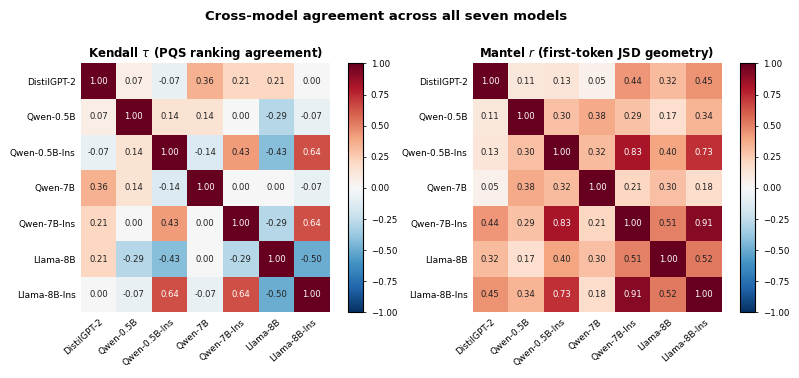

In [6]:

# Draw the two vector heatmaps

CMAP = mpl.colormaps["RdBu_r"]
NORM = Normalize(vmin=-1.0, vmax=1.0)
COLORBAR_TICKS = np.linspace(-1, 1, 9)

def relative_luminance(rgba):
    r, g, b = rgba[:3]
    return 0.2126*r + 0.7152*g + 0.0722*b

def draw_vector_heatmap(ax, matrix, labels, title):
    n = matrix.shape[0]

    for row in range(n):
        for col in range(n):
            value = float(matrix[row, col])
            face = CMAP(NORM(value))

            ax.add_patch(Rectangle(
                (col, row), 1, 1,
                facecolor=face,
                edgecolor="none",
                linewidth=0,
                rasterized=False,
            ))

            text_color = "white" if relative_luminance(face) < 0.48 else "#222222"
            ax.text(
                col + 0.5, row + 0.5, f"{value:.2f}",
                ha="center", va="center",
                fontsize=6.1, color=text_color,
            )

    ax.set_xlim(0, n)
    ax.set_ylim(n, 0)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(n) + 0.5)
    ax.set_yticks(np.arange(n) + 0.5)
    ax.set_xticklabels(labels, rotation=42, ha="right", rotation_mode="anchor")
    ax.set_yticklabels(labels)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontweight="bold", pad=5)

    for spine in ax.spines.values():
        spine.set_visible(False)

    return ScalarMappable(norm=NORM, cmap=CMAP)

fig = plt.figure(figsize=(7.6, 4.05))

# 5 columns: heatmap | colorbar | SPACER | heatmap | colorbar
# The spacer column reserves room for the second panel's y tick labels so they
# can never collide with the first panel's colorbar.
gs = fig.add_gridspec(
    1, 5,
    width_ratios=[1.0, 0.055, 0.30, 1.0, 0.055],
    wspace=0.10,
)

ax_k = fig.add_subplot(gs[0, 0])
cax_k = fig.add_subplot(gs[0, 1])
# gs[0, 2] is intentionally left empty (spacer)
ax_m = fig.add_subplot(gs[0, 3])
cax_m = fig.add_subplot(gs[0, 4])

mk = draw_vector_heatmap(
    ax_k, kendall_matrix, model_labels,
    r"Kendall $\tau$ (PQS ranking agreement)"
)
mm = draw_vector_heatmap(
    ax_m, mantel_matrix, model_labels,
    r"Mantel $r$ (first-token JSD geometry)"
)

cb1 = fig.colorbar(mk, cax=cax_k, ticks=COLORBAR_TICKS)
cb2 = fig.colorbar(mm, cax=cax_m, ticks=COLORBAR_TICKS)
cb1.ax.tick_params(labelsize=6.2, length=2.3, width=0.55)
cb2.ax.tick_params(labelsize=6.2, length=2.3, width=0.55)

fig.suptitle(
    "Cross-model agreement across all seven models",
    fontsize=9.5, fontweight="bold", y=0.992
)

fig.subplots_adjust(left=0.090, right=0.985, top=0.86, bottom=0.245)
plt.show()


In [7]:

# Export vector master + backups

PDF_NAME = "agreement_heatmaps_7models_vector.pdf"
SVG_NAME = "agreement_heatmaps_7models_vector.svg"
PNG_NAME = "agreement_heatmaps_7models_preview_600dpi.png"

fig.savefig(f"/content/{PDF_NAME}", format="pdf", bbox_inches="tight", pad_inches=0.03)
fig.savefig(f"/content/{SVG_NAME}", format="svg", bbox_inches="tight", pad_inches=0.03)
fig.savefig(f"/content/{PNG_NAME}", format="png", dpi=600, bbox_inches="tight", pad_inches=0.03)

kendall_df.to_csv("/content/kendall_full_pqs_matrix.csv")
mantel_df.to_csv("/content/mantel_agreement_matrix.csv")

print("Saved:")
print(" ", f"/content/{PDF_NAME}")
print(" ", f"/content/{SVG_NAME}")
print(" ", f"/content/{PNG_NAME}")


Saved:
  /content/agreement_heatmaps_7models_vector.pdf
  /content/agreement_heatmaps_7models_vector.svg
  /content/agreement_heatmaps_7models_preview_600dpi.png


In [8]:

# Download the Springer-ready PDF

from google.colab import files
files.download("/content/agreement_heatmaps_7models_vector.pdf")

# Optional:
# files.download("/content/agreement_heatmaps_7models_vector.svg")
# files.download("/content/agreement_heatmaps_7models_preview_600dpi.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Using the PDF in LaTeX

```latex
\begin{figure*}[t]
    \centering
    \includegraphics[width=\textwidth]{agreement_heatmaps_7models_vector.pdf}
    \caption{...}
    \label{fig:cross_model_agreement}
\end{figure*}
```

Use the PDF directly; do not convert it to a raster format.